# Are Academic Factors or Lifestyle Factors More Strongly Associated With Students' Final Grades?

# 1. Import libraries and dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('student-por.csv')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


# 2. Dataset Overview

## Dataset Features Description

| Column | Description | Values / Scale |
|---|---|---|
| school | Student's school | GP = Gabriel Pereira; MS = Mousinho da Silveira |
| sex | Student's sex | F = Female; M = Male |
| age | Student's age | 15–22 years |
| address | Home address type | U = Urban; R = Rural |
| famsize | Family size | LE3 = 3 or fewer; GT3 = more than 3 |
| Pstatus | Parents' cohabitation status | T = Together; A = Apart |
| Medu | Mother's education level | 0 = None; 1 = Primary (4th grade); 2 = 5th–9th grade; 3 = Secondary; 4 = Higher education |
| Fedu | Father's education level | 0 = None; 1 = Primary (4th grade); 2 = 5th–9th grade; 3 = Secondary; 4 = Higher education |
| Mjob | Mother's occupation | teacher, health, services, at_home, other |
| Fjob | Father's occupation | teacher, health, services, at_home, other |
| reason | Reason for choosing the school | home, reputation, course, other |
| guardian | Student's guardian | mother, father, other |
| traveltime | Travel time from home to school | 1 = <15 min; 2 = 15–30 min; 3 = 30–60 min; 4 = >60 min |
| studytime | Weekly study time | 1 = <2 hours; 2 = 2–5 hours; 3 = 5–10 hours; 4 = >10 hours |
| failures | Number of previous class failures | 0–3, with 4 representing 4 or more |
| schoolsup | Extra educational support from school | yes / no |
| famsup | Family educational support | yes / no |
| paid | Extra paid classes in the course subject | yes / no |
| activities | Participation in extracurricular activities | yes / no |
| nursery | Attended nursery school | yes / no |
| higher | Wants to pursue higher education | yes / no |
| internet | Internet access at home | yes / no |
| romantic | In a romantic relationship | yes / no |
| famrel | Quality of family relationships | 1 = Very bad; 5 = Excellent |
| freetime | Free time after school | 1 = Very low; 5 = Very high |
| goout | Frequency of going out with friends | 1 = Very low; 5 = Very high |
| Dalc | Workday alcohol consumption | 1 = Very low; 5 = Very high |
| Walc | Weekend alcohol consumption | 1 = Very low; 5 = Very high |
| health | Current health status | 1 = Very bad; 5 = Very good |
| absences | Number of school absences | 0–93 |
| G1 | First-period grade | 0–20 |
| G2 | Second-period grade | 0–20 |
| G3 | Final grade | 0–20 |

**Source:** Cortez, P. (2008). Student Performance. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

# 3. Data Understanding
## 3.1 Dataset Shape And Structure

In [3]:
df.shape

(649, 33)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

## 3.2 Checking Missing Values And Duplicates

In [5]:
df.isna().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [6]:
df.duplicated().sum() #no duplicates/null values

np.int64(0)

## 3.3 Descriptive Statistics

In [7]:
df.describe().T #transpose to get a proper view on all features

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.568567,0.748660,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.930663,0.829510,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.221880,0.593235,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.930663,0.955717,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.184900,1.175766,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.502311,0.924834,1.0,1.0,1.0,2.0,5.0


# 4. Data Cleaning and Validation
## 4.1 Categorical Consistency


In [8]:
for col in df.select_dtypes(include="object"):
    print(df[col].value_counts(),'\n')

school
GP    423
MS    226
Name: count, dtype: int64 

sex
F    383
M    266
Name: count, dtype: int64 

address
U    452
R    197
Name: count, dtype: int64 

famsize
GT3    457
LE3    192
Name: count, dtype: int64 

Pstatus
T    569
A     80
Name: count, dtype: int64 

Mjob
other       258
services    136
at_home     135
teacher      72
health       48
Name: count, dtype: int64 

Fjob
other       367
services    181
at_home      42
teacher      36
health       23
Name: count, dtype: int64 

reason
course        285
home          149
reputation    143
other          72
Name: count, dtype: int64 

guardian
mother    455
father    153
other      41
Name: count, dtype: int64 

schoolsup
no     581
yes     68
Name: count, dtype: int64 

famsup
yes    398
no     251
Name: count, dtype: int64 

paid
no     610
yes     39
Name: count, dtype: int64 

activities
no     334
yes    315
Name: count, dtype: int64 

nursery
yes    521
no     128
Name: count, dtype: int64 

higher
yes    580
no      

## 4.2 Numerical Range Validation

In [9]:
df[['age', 'studytime', 'famrel',
    'freetime', 'goout', 'health',
    'absences', 'G1', 'G2', 'G3']].describe().T

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
studytime,649.0,1.930663,0.829510,1.0,1.0,2.0,2.0,4.0
famrel,649.0,3.930663,0.955717,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180277,1.051093,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.184900,1.175766,1.0,2.0,3.0,4.0,5.0
health,649.0,3.536210,1.446259,1.0,2.0,4.0,5.0,5.0
absences,649.0,3.659476,4.640759,0.0,0.0,2.0,6.0,32.0
G1,649.0,11.399076,2.745265,0.0,10.0,11.0,13.0,19.0
G2,649.0,11.570108,2.913639,0.0,10.0,11.0,13.0,19.0
G3,649.0,11.906009,3.230656,0.0,10.0,12.0,14.0,19.0


## 4.3 Outlier Investigation

In [10]:
invalid_grades = (~df['G3'].between(0, 20)).sum()
print("Invalid final grades:", invalid_grades) #no invalid final grades

print(df['studytime'].value_counts().sort_index())

Invalid final grades: 0
studytime
1    212
2    305
3     97
4     35
Name: count, dtype: int64


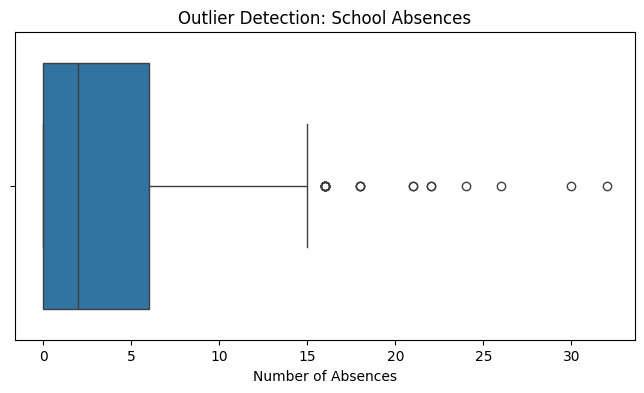

In [11]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='absences')

plt.title('Outlier Detection: School Absences')
plt.xlabel('Number of Absences')
plt.show()

In [12]:
Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['absences'] < lower) |
    (df['absences'] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))

Lower bound: -9.0
Upper bound: 15.0
Number of outliers: 21


In [13]:
df['absence_outlier'] = (
    (df['absences'] < lower) |
    (df['absences'] > upper)
)

df.groupby('absence_outlier')['G3'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
absence_outlier,,,
False,628,11.944268,12.0
True,21,10.761905,10.0


In [14]:
outliers[
    ['absences', 'G3', 'studytime',
     'failures', 'goout', 'health']
].sort_values(by='absences', ascending=False)

,absences,G3,studytime,failures,goout,health
197,32,14,2,0,3,1
212,30,16,1,1,4,2
256,26,8,1,1,3,1
150,24,9,2,0,2,1
155,22,6,1,0,5,5
325,22,10,1,0,4,5
217,21,13,1,0,2,3
413,21,10,2,2,3,4
326,18,13,1,0,4,3
397,18,14,2,0,1,4


### Data validation summary

The dataset has no missing values or exact duplicate rows. The absence outliers appear plausible, so they are kept for analysis.

no major cleaning or preprocessing changes were necessary.


# 5. Exploratory Data Analysis

**Research question:** Are academic factors or lifestyle factors more strongly associated with final grades?


## 5.1 Feature groups

In [15]:
academic_cols = ['studytime', 'failures', 'absences', 'schoolsup', 'famsup', 'higher']
lifestyle_cols = ['goout', 'freetime', 'famrel', 'romantic', 'activities', 'health']
background_cols = ['age', 'sex', 'Medu', 'Fedu', 'address', 'school']

## 5.2 Univariate Analysis

First, look at the distribution of grades and some student characteristics.

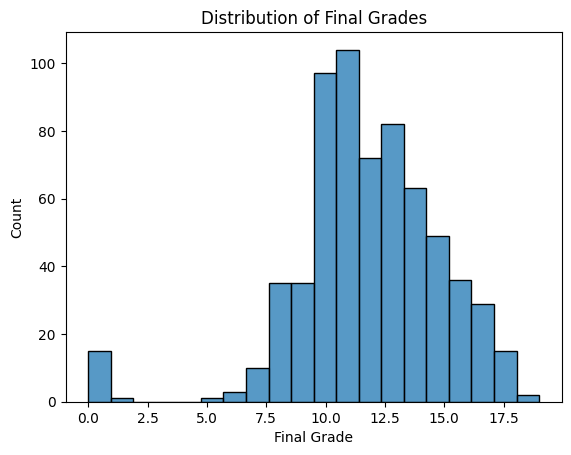

In [16]:
# check how final grades are distributed across students
sns.histplot(data=df, x='G3', bins=20)
plt.title('Distribution of Final Grades')
plt.xlabel('Final Grade')
plt.show()

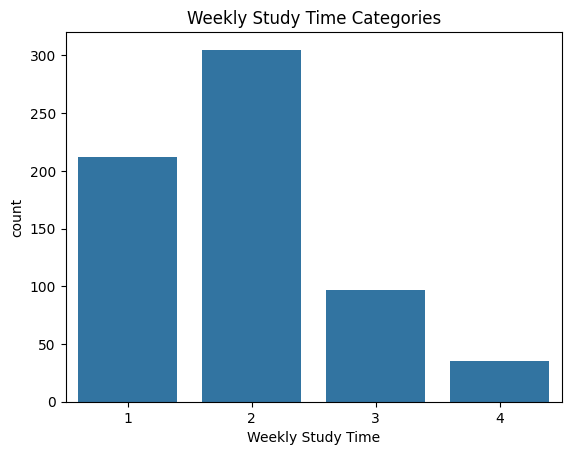

In [17]:
# see which weekly study-time category is most common
sns.countplot(data=df, x='studytime')
plt.title('Weekly Study Time Categories')
plt.xlabel('Weekly Study Time')
plt.show()

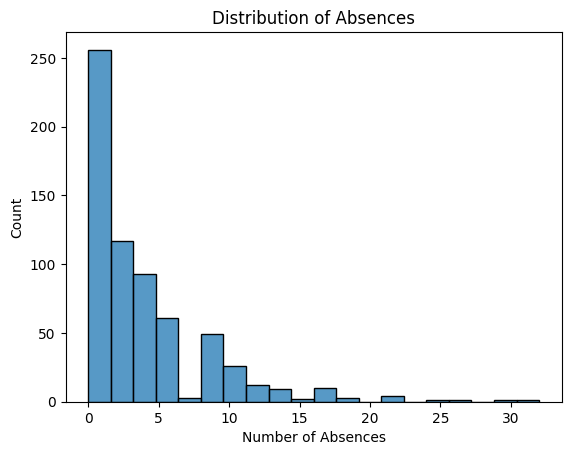

In [18]:
# see whether most students have few absences or many
sns.histplot(data=df, x='absences', bins=20)
plt.title('Distribution of Absences')
plt.xlabel('Number of Absences')
plt.show()

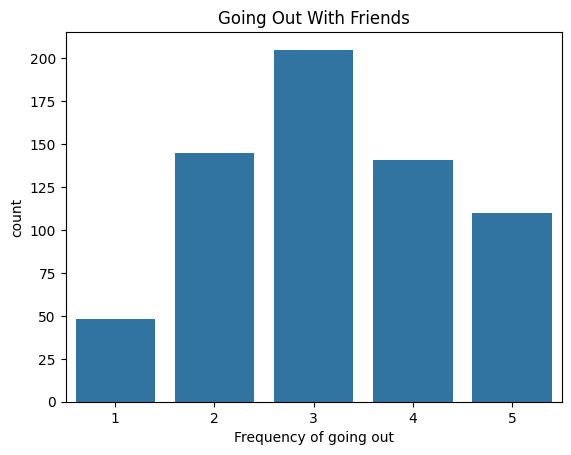

In [19]:
# explore how frequently students go out with friends
sns.countplot(data=df, x='goout')
plt.title('Going Out With Friends')
plt.xlabel('Frequency of going out')
plt.show()

## 5.3 Bivariate Analysis — Academic Factors

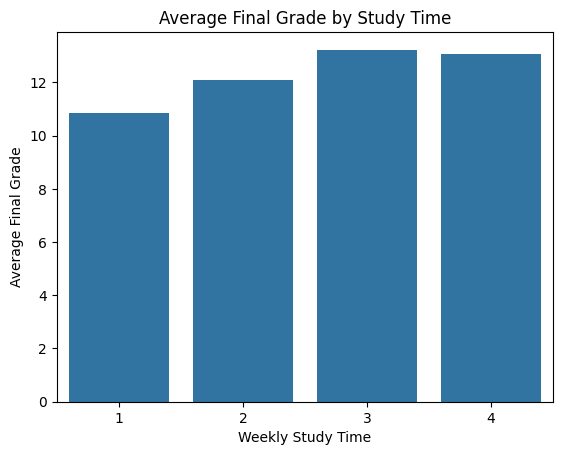

In [20]:
# compare average final grades across study-time categories
# do students who study more tend to score higher?
sns.barplot(data=df, x='studytime', y='G3', errorbar=None)
plt.title('Average Final Grade by Study Time')
plt.xlabel('Weekly Study Time')
plt.ylabel('Average Final Grade')
plt.show()

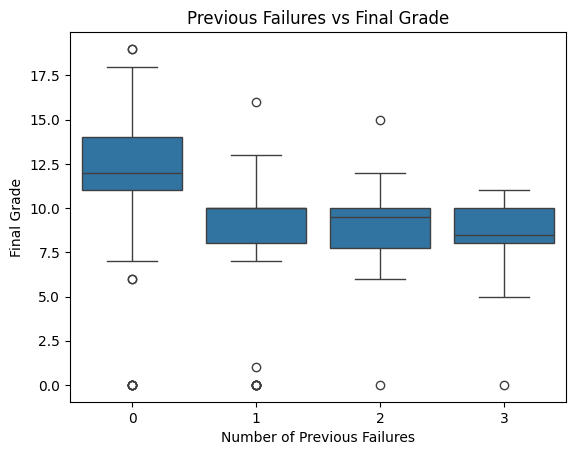

In [21]:
# check how previous class failures relate to final grades
# boxplot shows the spread of grades, not only the average
sns.boxplot(data=df, x='failures', y='G3')
plt.title('Previous Failures vs Final Grade')
plt.xlabel('Number of Previous Failures')
plt.ylabel('Final Grade')
plt.show()

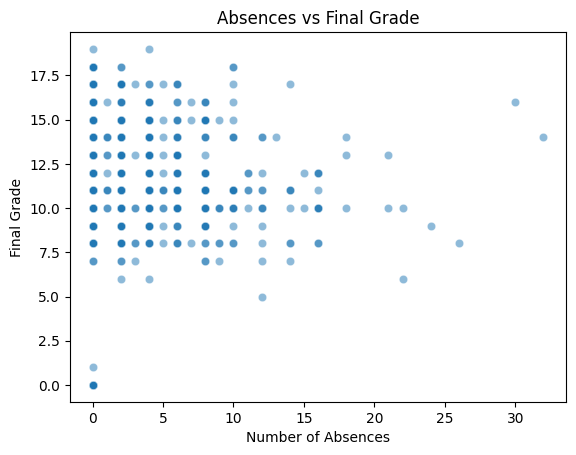

In [22]:
# investigate whether absences and grades move together
sns.scatterplot(data=df, x='absences', y='G3', alpha=0.5)
plt.title('Absences vs Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade')
plt.show()

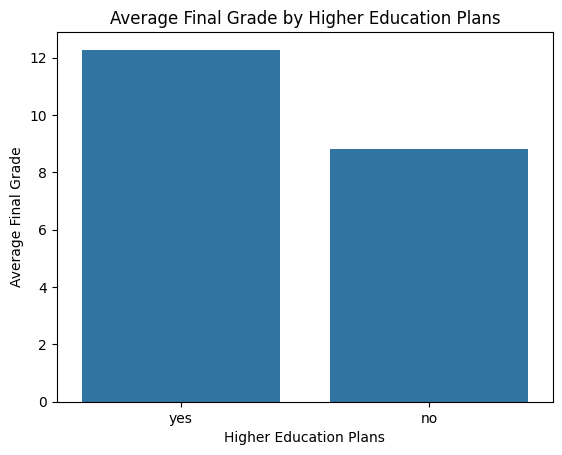

In [23]:
# compare average grades of students who want higher education and those who do not
sns.barplot(data=df, x='higher', y='G3', errorbar=None)
plt.title('Average Final Grade by Higher Education Plans')
plt.xlabel('Higher Education Plans')
plt.ylabel('Average Final Grade')
plt.show()

In [24]:
df.groupby('studytime')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
studytime,,,
1,212,10.84,11.0
2,305,12.09,12.0
3,97,13.23,13.0
4,35,13.06,13.0


## 5.4 Bivariate Analysis — Lifestyle and Social Factors

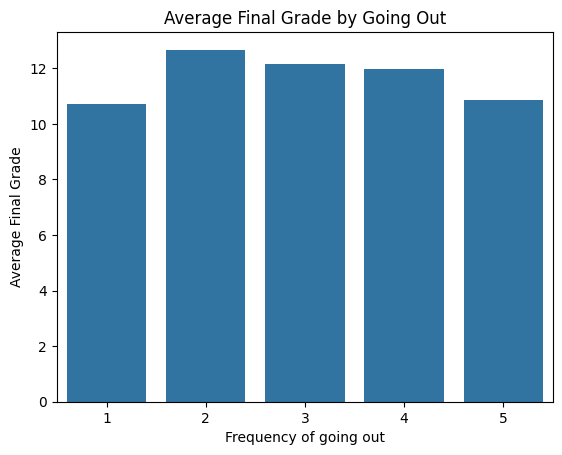

In [25]:
# check whether going out more often is associated with different average grades
sns.barplot(data=df, x='goout', y='G3', errorbar=None)
plt.title('Average Final Grade by Going Out')
plt.xlabel('Frequency of going out')
plt.ylabel('Average Final Grade')
plt.show()

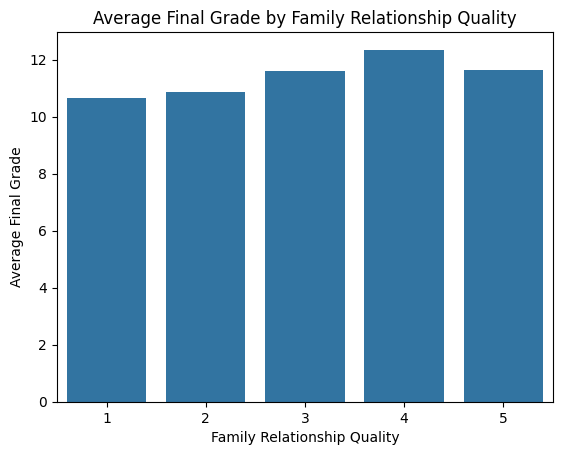

In [26]:
# explore whether family relationship ratings relate to average grades
sns.barplot(data=df, x='famrel', y='G3', errorbar=None)
plt.title('Average Final Grade by Family Relationship Quality')
plt.xlabel('Family Relationship Quality')
plt.ylabel('Average Final Grade')
plt.show()

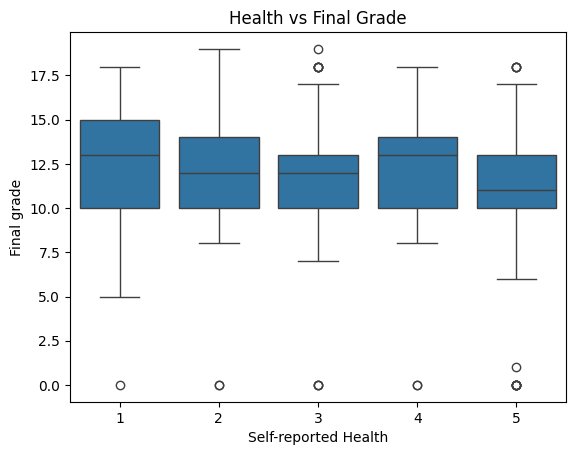

In [27]:
# check whether self-reported health is related to grades
sns.boxplot(data=df, x='health', y='G3')
plt.ylabel('Final grade')
plt.xlabel('Self-reported Health')
plt.title('Health vs Final Grade')
plt.show()

In [28]:
df.groupby('goout')['G3'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
goout,,,
1,48,10.73,11.0
2,145,12.67,13.0
3,205,12.15,12.0
4,141,11.97,12.0
5,110,10.87,11.0


## 5.5 Background Factors

These help provide context, but are not the main academic-vs-lifestyle comparison.

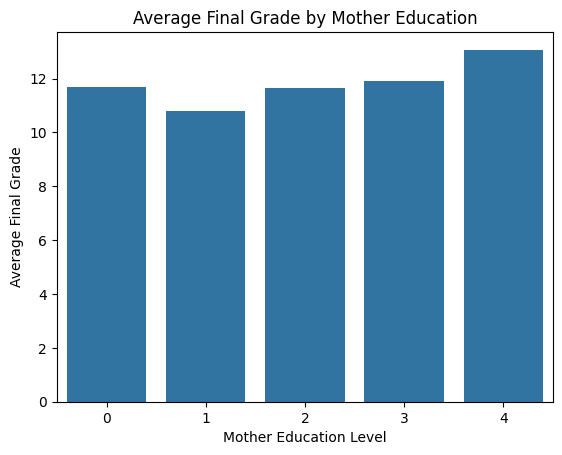

In [29]:
# explore the relationship between mother's education and final grades
sns.barplot(data=df, x='Medu', y='G3', errorbar=None)
plt.title('Average Final Grade by Mother Education')
plt.ylabel('Average Final Grade')
plt.xlabel('Mother Education Level')
plt.show()

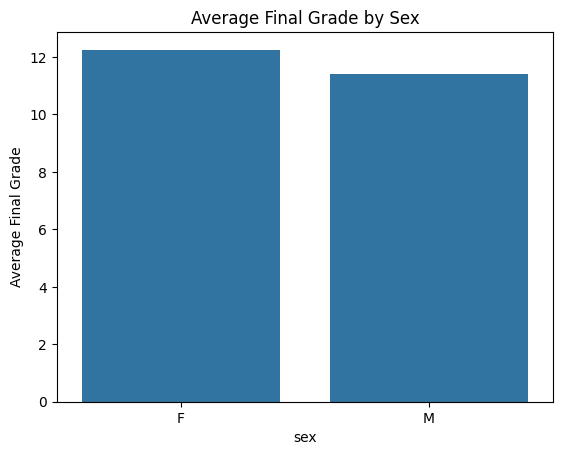

In [30]:
# compare average final grades by sex (descriptive comparison only)
sns.barplot(data=df, x='sex', y='G3', errorbar=None)
plt.title('Average Final Grade by Sex')
plt.ylabel('Average Final Grade')
plt.show()

## 5.6 Multivariate Analysis

A heatmap is useful for comparing several numeric or ordered variables at once. Spearman correlation works well for ordered scales such as study time and socializing.

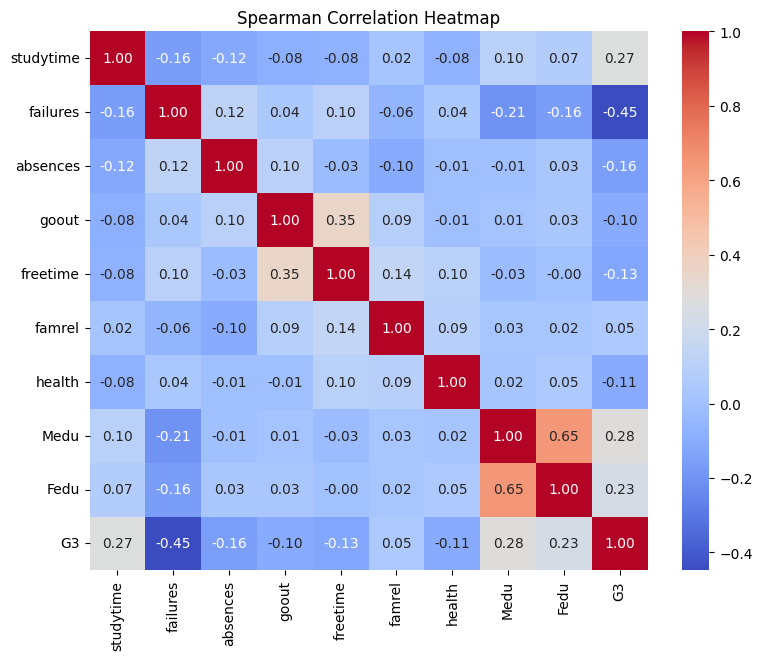

In [31]:
# spearman correlation compares ordered/numerical variables with each other
# correlation shows association, not cause and effect
selected = ['studytime', 'failures', 'absences', 'goout', 'freetime', 'famrel', 'health', 'Medu', 'Fedu', 'G3']
plt.figure(figsize=(9, 7))
sns.heatmap(df[selected].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Spearman Correlation Heatmap')
plt.show()

## 5.7 Compare Academic and Lifestyle Associations

The following compares **individual numeric/ordinal features** with final grades. It is a simple descriptive comparison, not proof that one whole group causes grades or is more important.

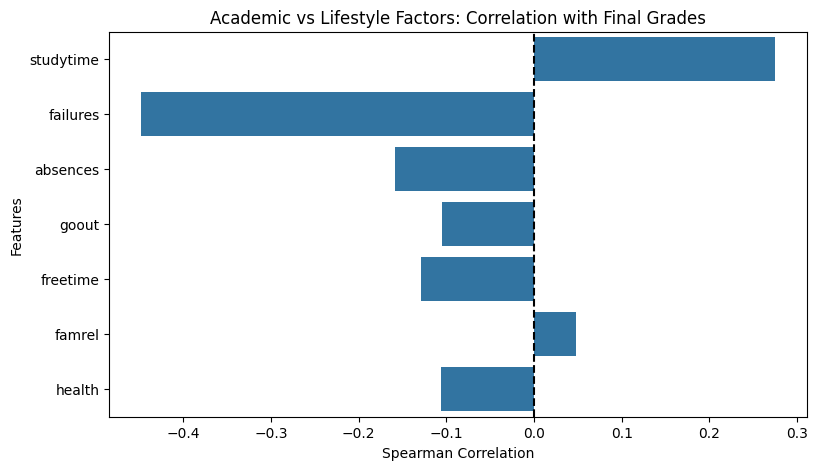

In [32]:
# compare academic and lifestyle factors based on their correlation with final grades

features = ['studytime', 'failures', 'absences','goout', 'freetime', 'famrel', 'health']

# calculate Spearman correlation with final grades
correlations = df[features + ['G3']].corr(method='spearman')['G3'].drop('G3')

plt.figure(figsize=(9, 5))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title('Academic vs Lifestyle Factors: Correlation with Final Grades')
plt.xlabel('Spearman Correlation')
plt.ylabel('Features')
plt.axvline(0, color='black', linestyle='--')
plt.show()

## 5.8 Previous Grades (Separate Benchmark)

Earlier grades measure academic performance directly, so we compare them separately instead of including them in the academic-factor group.

In [33]:
df[['G1', 'G2', 'G3']].corr(method='spearman').round(2)

,G1,G2,G3
G1,1.00,0.89,0.88
G2,0.89,1.00,0.94
G3,0.88,0.94,1.00


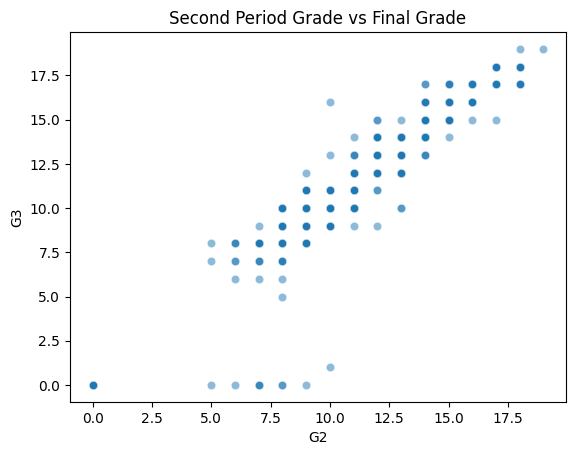

In [34]:
# compare second-period and final grades; these are two assessments of the same course
sns.scatterplot(data=df, x='G2', y='G3', alpha=0.5)
plt.title('Second Period Grade vs Final Grade')
plt.show()

## 5.9 Export Validated Dataset

In [35]:
clean_df = df.drop(columns=['absence_outlier'], errors='ignore')
clean_df.to_csv('student_performance_clean.csv', index=False)

# 6. Key Findings and Conclusion

## 6.1 Key Findings

**1. Final Grade Distribution**

The dataset contains 649 students, with an average final grade of **11.91 out of 20** and a median of 12. Most students scored between 10 and 14.

**2. Academic Factors**

Academic factors showed noticeable relationships with final grades.

- **Previous failures** had the strongest negative correlation among the selected academic and lifestyle variables (Spearman r = -0.448). Students with no previous failures had an average grade of 12.51, compared with 8.64 for students with one previous failure.
- **Study time** had a positive correlation with final grades (r = 0.275). Students studying less than two hours per week averaged 10.84, while those studying 5–10 hours averaged 13.23.
- **Absences** showed a weak negative correlation with grades (r = -0.159), suggesting that students with more absences tended to have slightly lower grades.
- Students planning to pursue higher education had a higher average grade (12.28) than those without such plans (8.80).

**3. Lifestyle and Social Factors**

Lifestyle factors generally showed weaker relationships with final grades.

- **Going out with friends** had a weak negative correlation with grades (r = -0.105). Students in the highest going-out category averaged 10.87, compared with 12.67 in category 2.
- **Free time** had a weak negative correlation (r = -0.128).
- **Health** also had a weak negative correlation (r = -0.106).
- **Family relationship quality** showed almost no monotonic correlation with final grades (r = 0.048).

**4. Background Factors**

Parental education was positively associated with academic performance.

- Mother's education had a positive correlation with final grades (r = 0.284).
- Father's education also showed a positive correlation (r = 0.235).

These findings suggest that students' educational backgrounds may be relevant when examining differences in academic performance.

**5. Previous Grades**

Earlier academic performance had the strongest correlations with final grades. The second-period grade (`G2`) had a correlation of **0.944** with `G3`, while the first-period grade (`G1`) had a correlation of **0.883**.

These were analyzed separately because they directly measure academic performance rather than students' habits or lifestyle.

## 6.2 Conclusion

The analysis suggests that **the selected academic factors were generally more strongly associated with students' final grades than the selected lifestyle and social factors**.

Previous class failures showed the strongest negative association, while study time showed a positive association with academic performance. Lifestyle factors such as going out, free time, health, and family relationships generally showed weaker correlations.

Parental education also appeared to be relevant, highlighting the importance of considering students' backgrounds alongside their academic habits.

However, these findings are based on observational data from two Portuguese secondary schools. **Correlation does not imply causation**, and the results cannot establish that changing a particular behavior would directly improve students' grades.

Overall, the analysis demonstrates that academic performance is associated with several factors, with previous academic difficulties and study habits showing more noticeable relationships than the lifestyle variables examined.